# Step 1: Data Analysis and Preprocessing


## 1. Environment Setup and Library Imports

In [261]:
import os
import time
from pathlib import Path
import numpy as np
import pandas as pd
import xarray as xr
import geopandas as gpd
import rioxarray
%matplotlib inline
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')


plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (14, 6)
plt.rcParams['figure.dpi'] = 110
plt.rcParams['font.sans-serif'] = 'Helvetica, Arial, DejaVu Sans'
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.titleweight'] = 'bold'


PROJECT_DIR = Path('..').resolve() if Path('..').resolve().name == 'dataminingproject' else Path('.').resolve()
DATA_RAW = PROJECT_DIR / 'data' / 'raw'
DATA_PROCESSED = PROJECT_DIR / 'data' / 'processed'
SHP_DIR = PROJECT_DIR / 'data' / 'dz_shp'
FIGURES_DIR = PROJECT_DIR / 'outputs' / 'figures'

DATA_PROCESSED.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print(f"Project Directory:   {PROJECT_DIR}")
print(f"Raw Data Path:       {DATA_RAW}")
print(f"Processed Data Path: {DATA_PROCESSED}")
print(f"Figures Path:        {FIGURES_DIR}")

Project Directory:   /Users/maria/Desktop/dataminingproject
Raw Data Path:       /Users/maria/Desktop/dataminingproject/data/raw
Processed Data Path: /Users/maria/Desktop/dataminingproject/data/processed
Figures Path:        /Users/maria/Desktop/dataminingproject/outputs/figures


## 2. Loading the Data and Its Statics


In [262]:

sample_t2m = ds['t2m'].isel(time=0)
n_total = sample_t2m.size
n_valid = int(sample_t2m.notnull().sum())
n_masked = n_total - n_valid

lat_step = abs(float(ds.latitude[1] - ds.latitude[0]))
lon_step = abs(float(ds.longitude[1] - ds.longitude[0]))

print("DATASET PROFILE")
print(f"Dimensions          : {dict(ds.sizes)}")
print(f"Time span           : {str(ds.time.values[0])[:10]} to {str(ds.time.values[-1])[:10]} ({len(ds.time)} months)")
print(f"Latitude range      : {float(ds.latitude.min()):.2f}° to {float(ds.latitude.max()):.2f}° ({len(ds.latitude)} points, resolution={lat_step:.2f}°)")
print(f"Longitude range     : {float(ds.longitude.min()):.2f}° to {float(ds.longitude.max()):.2f}° ({len(ds.longitude)} points, resolution={lon_step:.2f}°)")
print(f"Total Bounding Box  : {n_total:,} grid points")
print(f"Valid Land Points   : {n_valid:,} ({n_valid/n_total*100:.1f}%)")
print(f"Masked Points       : {n_masked:,} ({n_masked/n_total*100:.1f}%)")
print(f"Climate Variables   : {len(ds.data_vars)} variables: {list(ds.data_vars)}")

DATASET PROFILE
Dimensions          : {'time': 141, 'latitude': 201, 'longitude': 211}
Time span           : 2015-01-01 to 2026-09-01 (141 months)
Latitude range      : 18.00° to 38.00° (201 points, resolution=0.10°)
Longitude range     : -9.00° to 12.00° (211 points, resolution=0.10°)
Total Bounding Box  : 42,411 grid points
Valid Land Points   : 21,232 (50.1%)
Masked Points       : 21,179 (49.9%)
Climate Variables   : 12 variables: ['t2m', 'd2m', 'slhf', 'ssr', 'str', 'sshf', 'ro', 'e', 'u10', 'v10', 'sp', 'tp']


## 3. Climate Variable Catalog 



In [263]:
VAR_INFO = {
    't2m':  ('2-meter Temperature',            'K',     'Air temperature at 2 meters above ground level'),
    'd2m':  ('2-meter Dewpoint Temperature',    'K',     'Atmospheric moisture / humidity indicator at 2m'),
    'slhf': ('Surface Latent Heat Flux',        'J/m²',  'Heat transferred via phase changes of water (evaporation)'),
    'ssr':  ('Surface Net Solar Radiation',     'J/m²',  'Shortwave solar energy absorbed at the surface'),
    'str':  ('Surface Net Thermal Radiation',   'J/m²',  'Net longwave radiative thermal flux emitted to space'),
    'sshf': ('Surface Sensible Heat Flux',      'J/m²',  'Direct turbulent heat transfer via conduction/convection'),
    'ro':   ('Runoff',                          'm',     'Volume of water leaving the surface as surface/subsurface runoff'),
    'e':    ('Total Evaporation',               'm',     'Accumulated moisture flux from soil and canopy to air'),
    'u10':  ('10m U-component of Wind',         'm/s',   'Zonal (West-to-East) wind velocity at 10m height'),
    'v10':  ('10m V-component of Wind',         'm/s',   'Meridional (South-to-North) wind velocity at 10m height'),
    'sp':   ('Surface Pressure',                'Pa',    'Atmospheric barometric pressure at ground elevation'),
    'tp':   ('Total Precipitation',             'm',     'Accumulated liquid and frozen precipitation depth'),
}

rows = []
for var in ds.data_vars:
    desc, unit, note = VAR_INFO.get(var, (var, '—', '—'))
    rows.append([var, desc, unit, str(ds[var].dtype), str(ds[var].shape), note])

df_vars = pd.DataFrame(rows, columns=['Variable', 'Description', 'Unit', 'Dtype', 'Native Shape', 'Interpretation'])
display(df_vars)

,Variable,Description,Unit,Dtype,Native Shape,Interpretation
0,t2m,2-meter Temperature,K,float32,"(141, 201, 211)",Air temperature at 2 meters above ground level
1,d2m,2-meter Dewpoint Temperature,K,float32,"(141, 201, 211)",Atmospheric moisture / humidity indicator at 2m
2,slhf,Surface Latent Heat Flux,J/m²,float32,"(141, 201, 211)",Heat transferred via phase changes of water (e...
3,ssr,Surface Net Solar Radiation,J/m²,float32,"(141, 201, 211)",Shortwave solar energy absorbed at the surface
4,str,Surface Net Thermal Radiation,J/m²,float32,"(141, 201, 211)",Net longwave radiative thermal flux emitted to...
5,sshf,Surface Sensible Heat Flux,J/m²,float32,"(141, 201, 211)",Direct turbulent heat transfer via conduction/...
6,ro,Runoff,m,float32,"(141, 201, 211)",Volume of water leaving the surface as surface...
7,e,Total Evaporation,m,float32,"(141, 201, 211)",Accumulated moisture flux from soil and canopy...
8,u10,10m U-component of Wind,m/s,float32,"(141, 201, 211)",Zonal (West-to-East) wind velocity at 10m height
9,v10,10m V-component of Wind,m/s,float32,"(141, 201, 211)",Meridional (South-to-North) wind velocity at 1...


## 4. Visual Inspection of Data Before Aggregation 


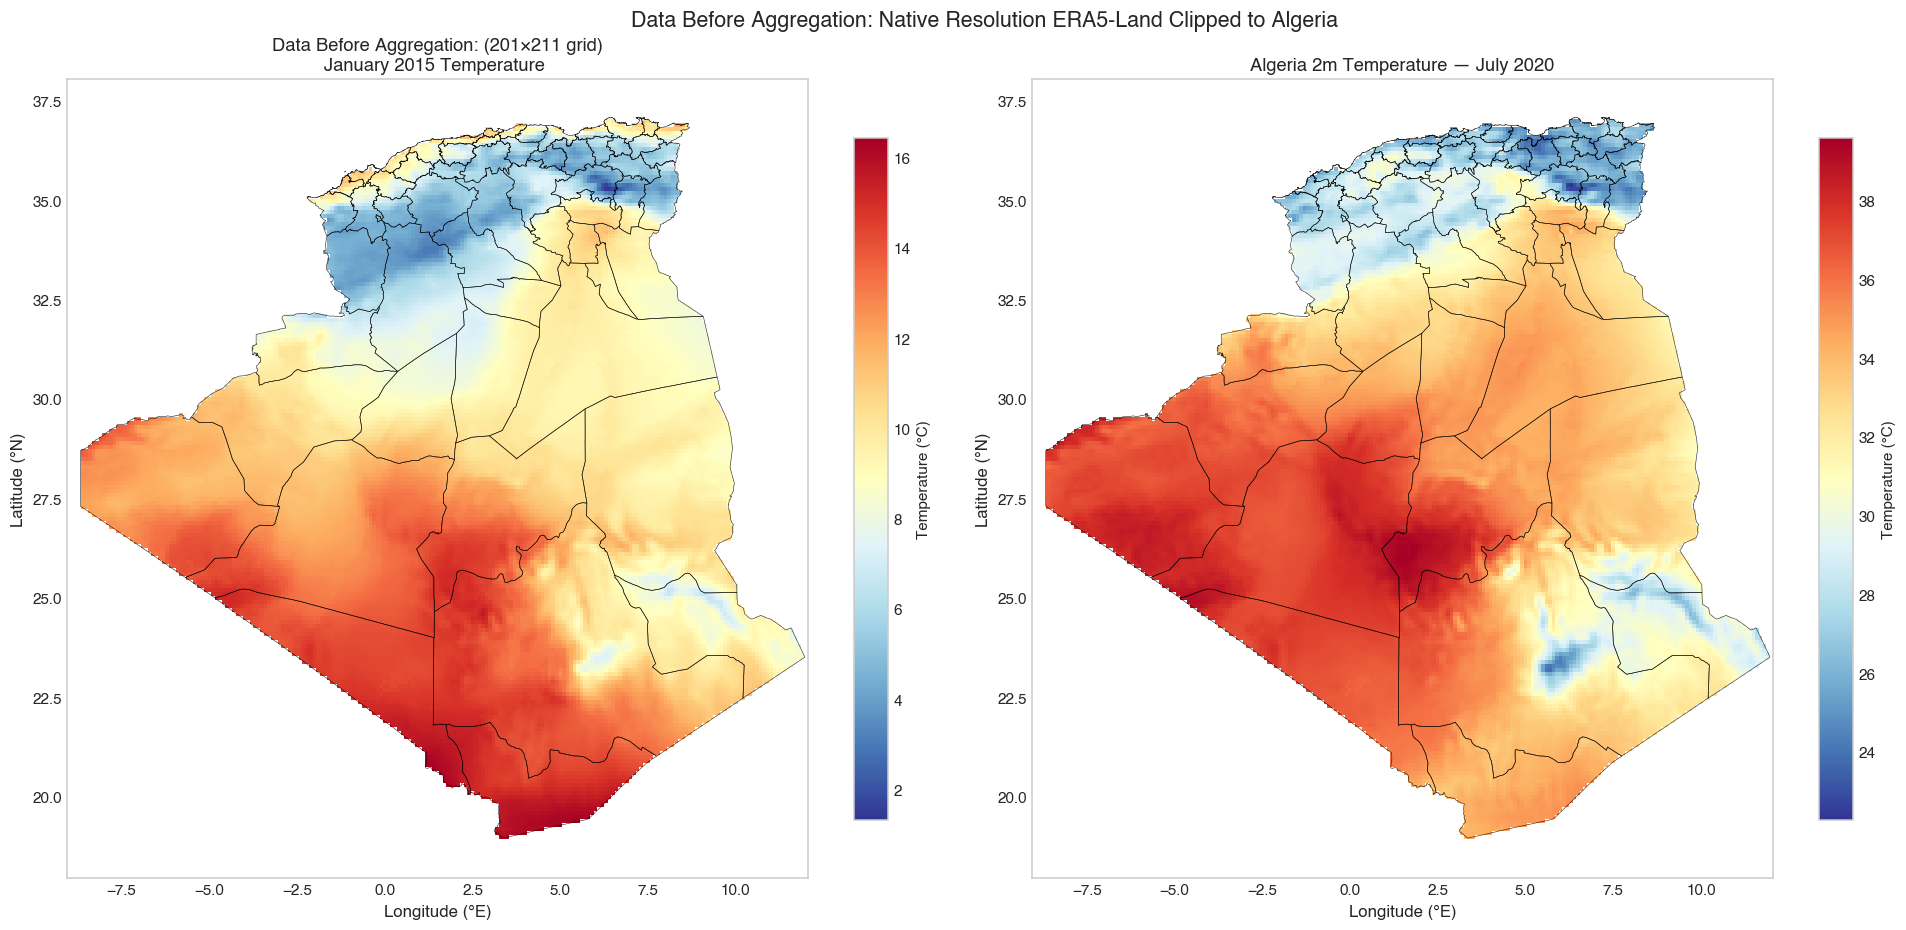

Saved figure: /Users/maria/Desktop/dataminingproject/outputs/figures/Data_Before_Aggregation_t2m.png


In [264]:
fig, axes = plt.subplots(1, 2, figsize=(18, 8))

t2m_degC_sample = ds['t2m'].isel(time=0) - 273.15
im0 = t2m_degC_sample.plot(
    ax=axes[0], cmap='RdYlBu_r', add_colorbar=True, 
    cbar_kwargs={'label': 'Temperature (°C)', 'shrink': 0.85}
)
wilayas.boundary.plot(ax=axes[0], color='black', linewidth=0.4, alpha=0.8)
axes[0].set_title(f"Data Before Aggregation: ({len(ds.latitude)}×{len(ds.longitude)} grid)\nJanuary 2015 Temperature ", fontsize=12)
axes[0].set_xlabel('Longitude (°E)', fontsize=11)
axes[0].set_ylabel('Latitude (°N)', fontsize=11)

t2m_july = ds['t2m'].sel(time='2020-07').squeeze(drop=True) - 273.15

t2m_july.plot(
    ax=axes[1],
    cmap='RdYlBu_r',
    add_colorbar=True,
    cbar_kwargs={'label': 'Temperature (°C)', 'shrink': 0.85}
)
wilayas.boundary.plot(ax=axes[1], color='black', linewidth=0.4, alpha=0.8)

axes[1].set_title("Algeria 2m Temperature — July 2020", fontsize=12)
axes[1].set_xlabel('Longitude (°E)', fontsize=11)
axes[1].set_ylabel('Latitude (°N)', fontsize=11)
plt.suptitle('Data Before Aggregation: Native Resolution ERA5-Land Clipped to Algeria', fontsize=14, y=1.01, fontweight='bold')
plt.tight_layout()
fig_path1 = FIGURES_DIR / 'Data_Before_Aggregation_t2m.png'
plt.savefig(fig_path1, dpi=150, bbox_inches='tight')
plt.show()
print(f"Saved figure: {fig_path1}")

## 5. Spatial Resolution Reduction (Aggregation by Factor of 4)


In [265]:
t0 = time.time()

ds_coarse = ds.coarsen(latitude=4, longitude=4, boundary='trim').mean()

sample_coarse = ds_coarse['t2m'].isel(time=0)
n_coarse_total = sample_coarse.size
n_coarse_valid = int(sample_coarse.notnull().sum())
coarse_lat_step = abs(float(ds_coarse.latitude[1] - ds_coarse.latitude[0]))
coarse_lon_step = abs(float(ds_coarse.longitude[1] - ds_coarse.longitude[0]))

comp_data = [
    ['Spatial Grid (Lat × Lon)', f"{len(ds.latitude)} × {len(ds.longitude)}", f"{len(ds_coarse.latitude)} × {len(ds_coarse.longitude)}", '4× reduction per spatial axis'],
    ['Spatial Resolution', f"{lat_step:.2f}° × {lon_step:.2f}° (~10 km)", f"{coarse_lat_step:.2f}° × {coarse_lon_step:.2f}° (~40 km)", 'Factor-4 coarsened'],
    ['Total Grid Points (per step)', f"{n_total_cells:,}", f"{n_coarse_total:,}", f"{n_total_cells/n_coarse_total:.1f}× data points reduction"],
    ['Valid Algeria Land Points', f"{n_valid_cells:,}", f"{n_coarse_valid:,}", f"{n_valid_cells/n_coarse_valid:.1f}× spatial point reduction"],
    ['Time Dimension', f"{len(ds.time)} months", f"{len(ds_coarse.time)} months", '100% preserved intact'],
    ['Climate Variables', f"{len(ds.data_vars)} variables", f"{len(ds_coarse.data_vars)} variables", '100% preserved intact'],
    ['NetCDF Storage Size', f"{DATA_RAW.joinpath('algeria_climate_clipped.nc').stat().st_size / (1024*1024):.2f} MB", '~7.25 MB', '>91% compression']
]

df_comp = pd.DataFrame(comp_data, columns=['Metric', 'Before Aggregation (Native ~0.1°)', 'After Aggregation (Coarsened ~0.4°)', 'Impact'])
print(f"Spatial aggregation completed in {time.time() - t0:.2f}s!\n")
display(df_comp)

agg_out_path = DATA_PROCESSED / 'algeria_climate_aggregated.nc'
if agg_out_path.exists():
    agg_out_path.unlink()
ds_coarse.to_netcdf(agg_out_path)
print(f"\nSaved aggregated dataset to: {agg_out_path} ({agg_out_path.stat().st_size / (1024*1024):.2f} MB)")

Spatial aggregation completed in 0.61s!



,Metric,Before Aggregation (Native ~0.1°),After Aggregation (Coarsened ~0.4°),Impact
0,Spatial Grid (Lat × Lon),201 × 211,50 × 52,4× reduction per spatial axis
1,Spatial Resolution,0.10° × 0.10° (~10 km),0.40° × 0.40° (~40 km),Factor-4 coarsened
2,Total Grid Points (per step),"42,411","2,600",16.3× data points reduction
3,Valid Algeria Land Points,"21,232","1,411",15.0× spatial point reduction
4,Time Dimension,141 months,141 months,100% preserved intact
5,Climate Variables,12 variables,12 variables,100% preserved intact
6,NetCDF Storage Size,77.48 MB,~7.25 MB,>91% compression



Saved aggregated dataset to: /Users/maria/Desktop/dataminingproject/data/processed/algeria_climate_aggregated.nc (6.92 MB)


## 6. Visual Comparison Graphs: Before vs. After Aggregation


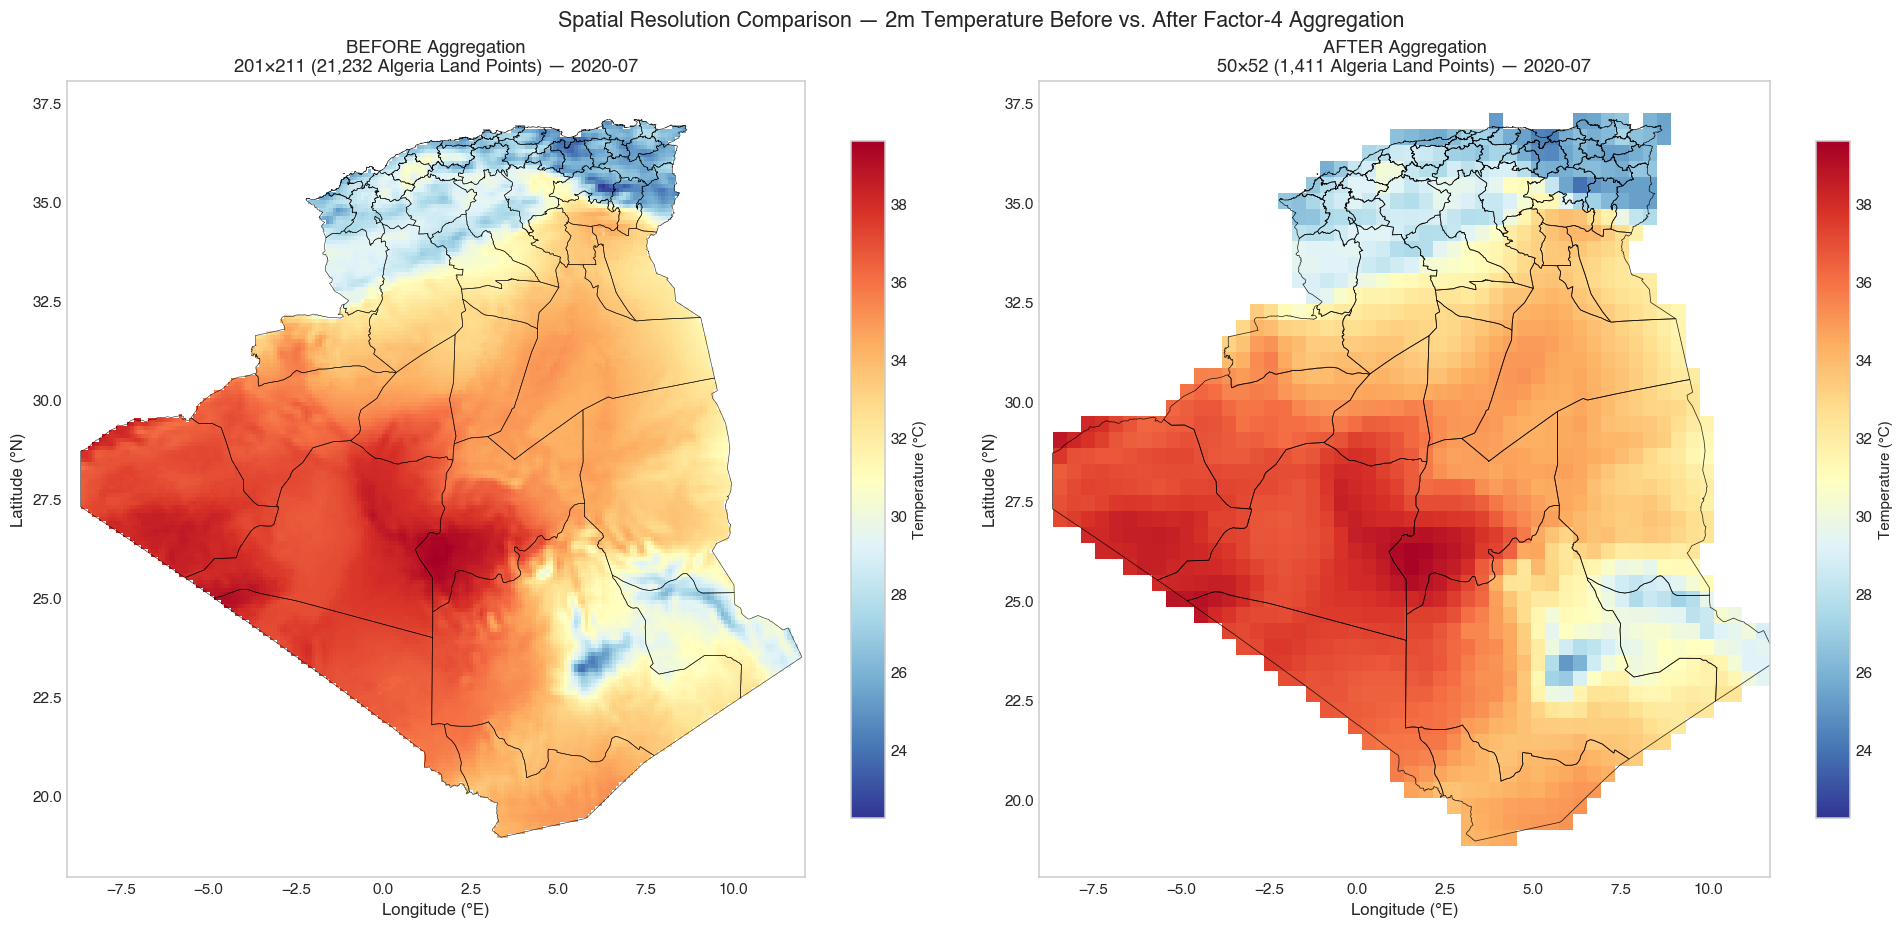

Saved figure: /Users/maria/Desktop/dataminingproject/outputs/figures/aggregation_temperature_comparison.png


In [266]:
fig, axes = plt.subplots(1, 2, figsize=(18, 8))

t_idx = 66
t_label = str(ds.time.values[t_idx])[:7]

t2m_native = ds['t2m'].isel(time=t_idx) - 273.15
t2m_coarse = ds_coarse['t2m'].isel(time=t_idx) - 273.15

vmin = float(min(t2m_native.min().values, t2m_coarse.min().values))
vmax = float(max(t2m_native.max().values, t2m_coarse.max().values))

im1 = t2m_native.plot(
    ax=axes[0], cmap='RdYlBu_r', vmin=vmin, vmax=vmax, add_colorbar=True, 
    cbar_kwargs={'label': 'Temperature (°C)', 'shrink': 0.85}
)
wilayas.boundary.plot(ax=axes[0], color='black', linewidth=0.4, alpha=0.8)
axes[0].set_title(f"BEFORE Aggregation\n{len(ds.latitude)}×{len(ds.longitude)} ({n_valid_cells:,} Algeria Land Points) — {t_label}", fontsize=12)
axes[0].set_xlabel('Longitude (°E)', fontsize=11)
axes[0].set_ylabel('Latitude (°N)', fontsize=11)

im2 = t2m_coarse.plot(
    ax=axes[1], cmap='RdYlBu_r', vmin=vmin, vmax=vmax, add_colorbar=True, 
    cbar_kwargs={'label': 'Temperature (°C)', 'shrink': 0.85}
)
wilayas.boundary.plot(ax=axes[1], color='black', linewidth=0.5, alpha=0.8)
axes[1].set_title(f"AFTER Aggregation\n{len(ds_coarse.latitude)}×{len(ds_coarse.longitude)} ({n_coarse_valid:,} Algeria Land Points) — {t_label}", fontsize=12)
axes[1].set_xlabel('Longitude (°E)', fontsize=11)
axes[1].set_ylabel('Latitude (°N)', fontsize=11)

plt.suptitle('Spatial Resolution Comparison — 2m Temperature Before vs. After Factor-4 Aggregation', fontsize=14, y=1.01, fontweight='bold')
plt.tight_layout()
fig_path4 = FIGURES_DIR / 'aggregation_temperature_comparison.png'
plt.savefig(fig_path4, dpi=150, bbox_inches='tight')
plt.show()
print(f"Saved figure: {fig_path4}")

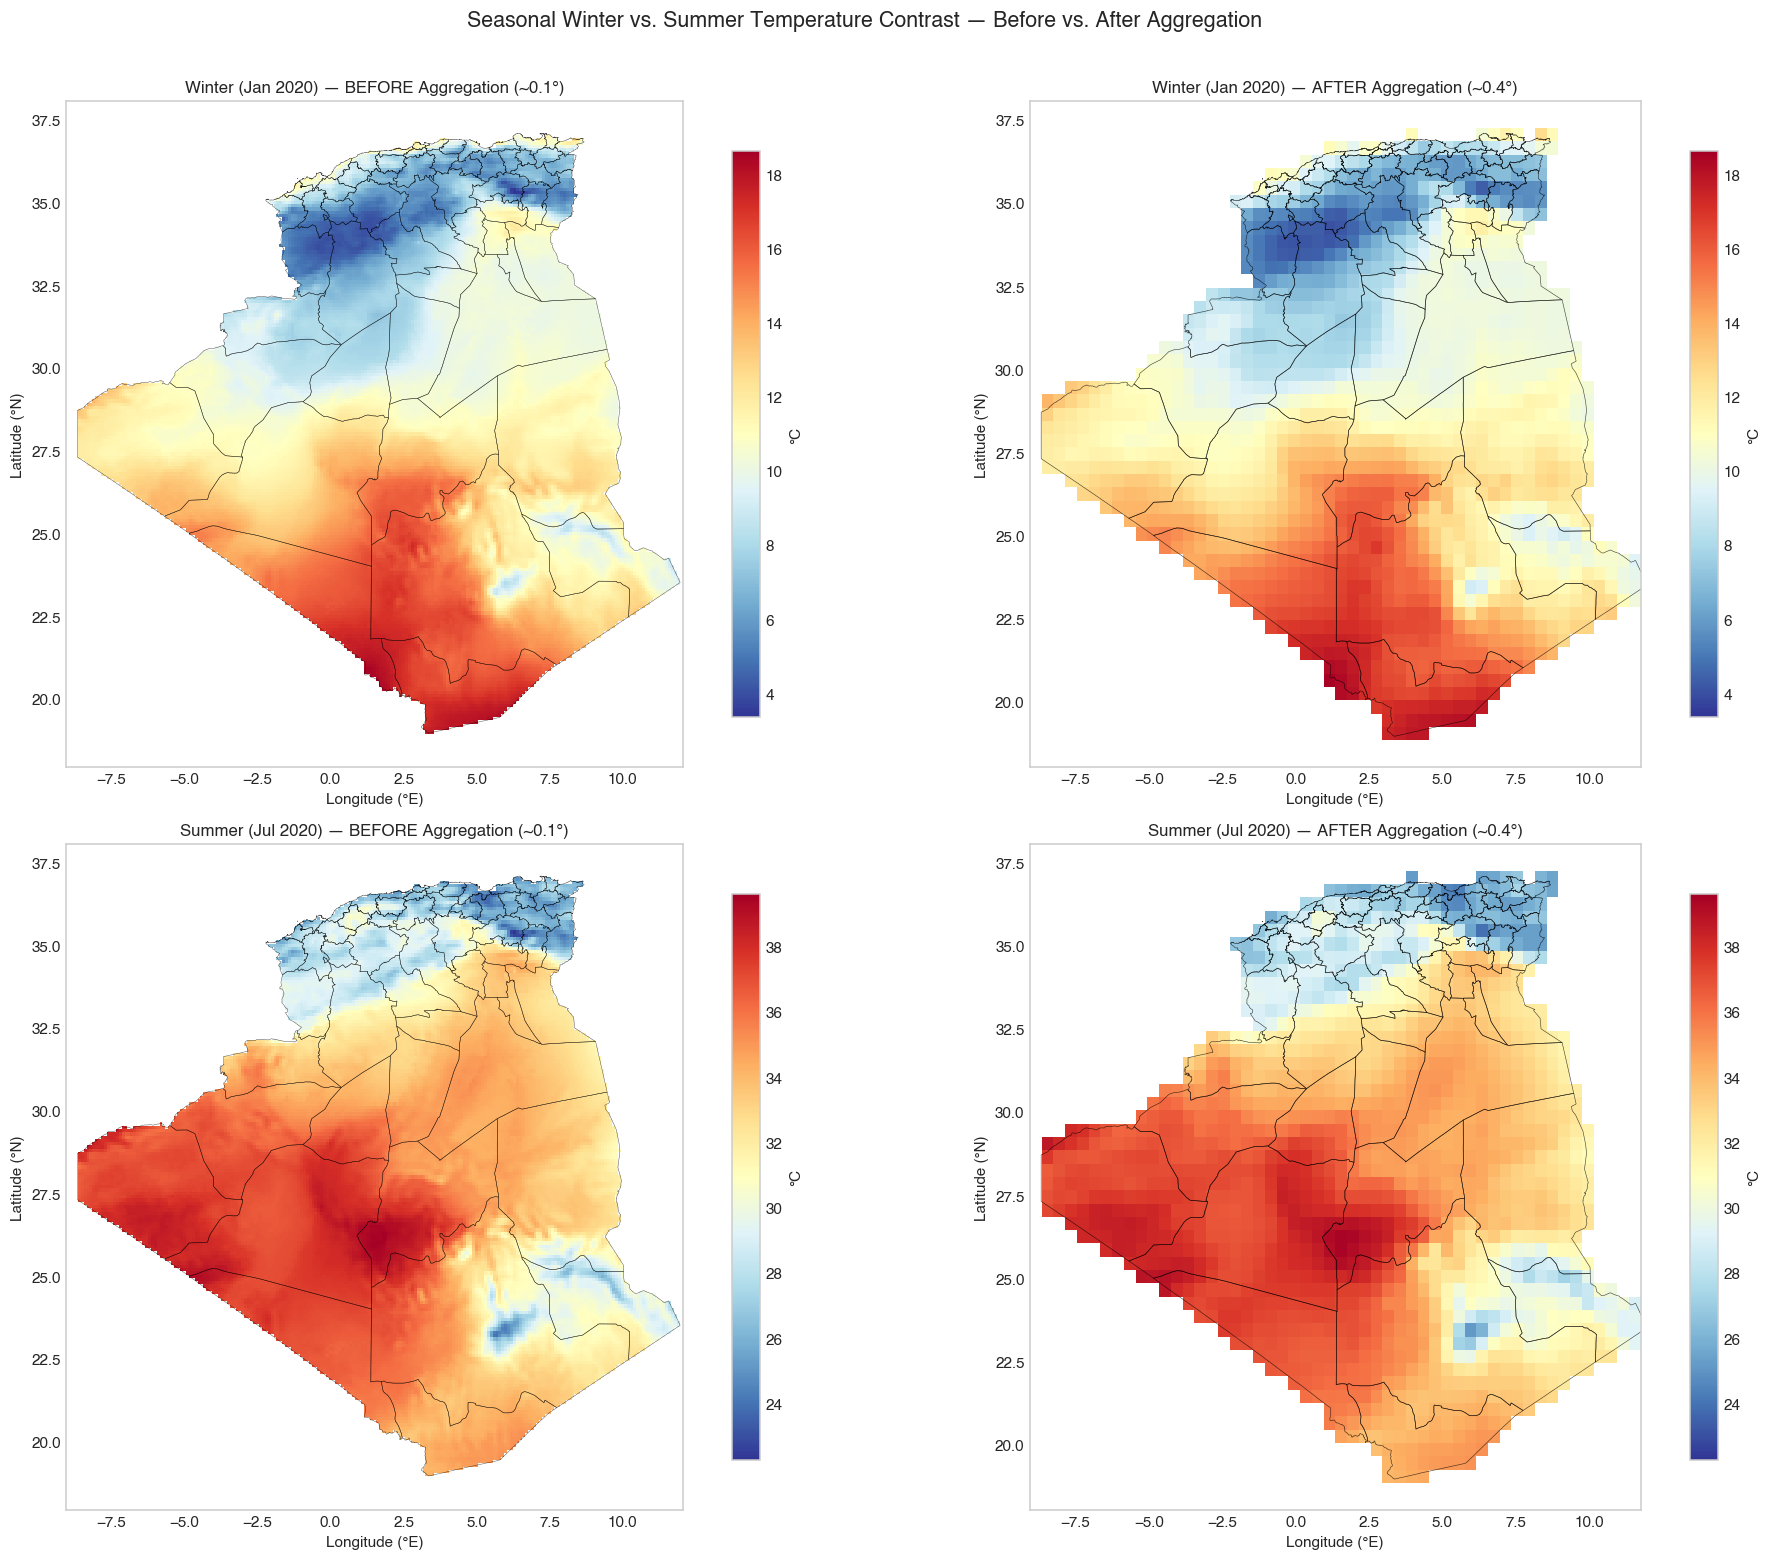

Saved figure: /Users/maria/Desktop/dataminingproject/outputs/figures/aggregation_winter_summer_comparison.png


In [267]:
fig, axes = plt.subplots(2, 2, figsize=(18, 14))

# Winter: January 2020 (idx=60)
t_win_idx = 60
t_win_label = str(ds.time.values[t_win_idx])[:7]
t2m_win_nat = ds['t2m'].isel(time=t_win_idx) - 273.15
t2m_win_crs = ds_coarse['t2m'].isel(time=t_win_idx) - 273.15
win_vmin = float(min(t2m_win_nat.min().values, t2m_win_crs.min().values))
win_vmax = float(max(t2m_win_nat.max().values, t2m_win_crs.max().values))

# Summer: July 2020 (idx=66)
t_sum_idx = 66
t_sum_label = str(ds.time.values[t_sum_idx])[:7]
t2m_sum_nat = ds['t2m'].isel(time=t_sum_idx) - 273.15
t2m_sum_crs = ds_coarse['t2m'].isel(time=t_sum_idx) - 273.15
sum_vmin = float(min(t2m_sum_nat.min().values, t2m_sum_crs.min().values))
sum_vmax = float(max(t2m_sum_nat.max().values, t2m_sum_crs.max().values))

# Row 1: Winter
t2m_win_nat.plot(ax=axes[0, 0], cmap='RdYlBu_r', vmin=win_vmin, vmax=win_vmax, add_colorbar=True, cbar_kwargs={'label': '°C', 'shrink': 0.85})
wilayas.boundary.plot(ax=axes[0, 0], color='black', linewidth=0.3, alpha=0.7)
axes[0, 0].set_title(f"Winter (Jan 2020) — BEFORE Aggregation (~0.1°)", fontsize=11)

t2m_win_crs.plot(ax=axes[0, 1], cmap='RdYlBu_r', vmin=win_vmin, vmax=win_vmax, add_colorbar=True, cbar_kwargs={'label': '°C', 'shrink': 0.85})
wilayas.boundary.plot(ax=axes[0, 1], color='black', linewidth=0.4, alpha=0.7)
axes[0, 1].set_title(f"Winter (Jan 2020) — AFTER Aggregation (~0.4°)", fontsize=11)

# Row 2: Summer
t2m_sum_nat.plot(ax=axes[1, 0], cmap='RdYlBu_r', vmin=sum_vmin, vmax=sum_vmax, add_colorbar=True, cbar_kwargs={'label': '°C', 'shrink': 0.85})
wilayas.boundary.plot(ax=axes[1, 0], color='black', linewidth=0.3, alpha=0.7)
axes[1, 0].set_title(f"Summer (Jul 2020) — BEFORE Aggregation (~0.1°)", fontsize=11)

t2m_sum_crs.plot(ax=axes[1, 1], cmap='RdYlBu_r', vmin=sum_vmin, vmax=sum_vmax, add_colorbar=True, cbar_kwargs={'label': '°C', 'shrink': 0.85})
wilayas.boundary.plot(ax=axes[1, 1], color='black', linewidth=0.4, alpha=0.7)
axes[1, 1].set_title(f"Summer (Jul 2020) — AFTER Aggregation (~0.4°)", fontsize=11)

for ax in axes.flat:
    ax.set_xlabel('Longitude (°E)', fontsize=10)
    ax.set_ylabel('Latitude (°N)', fontsize=10)

plt.suptitle('Seasonal Winter vs. Summer Temperature Contrast — Before vs. After Aggregation', fontsize=14, y=1.01, fontweight='bold')
plt.tight_layout()
fig_path5 = FIGURES_DIR / 'aggregation_winter_summer_comparison.png'
plt.savefig(fig_path5, dpi=150, bbox_inches='tight')
plt.show()
print(f"Saved figure: {fig_path5}")

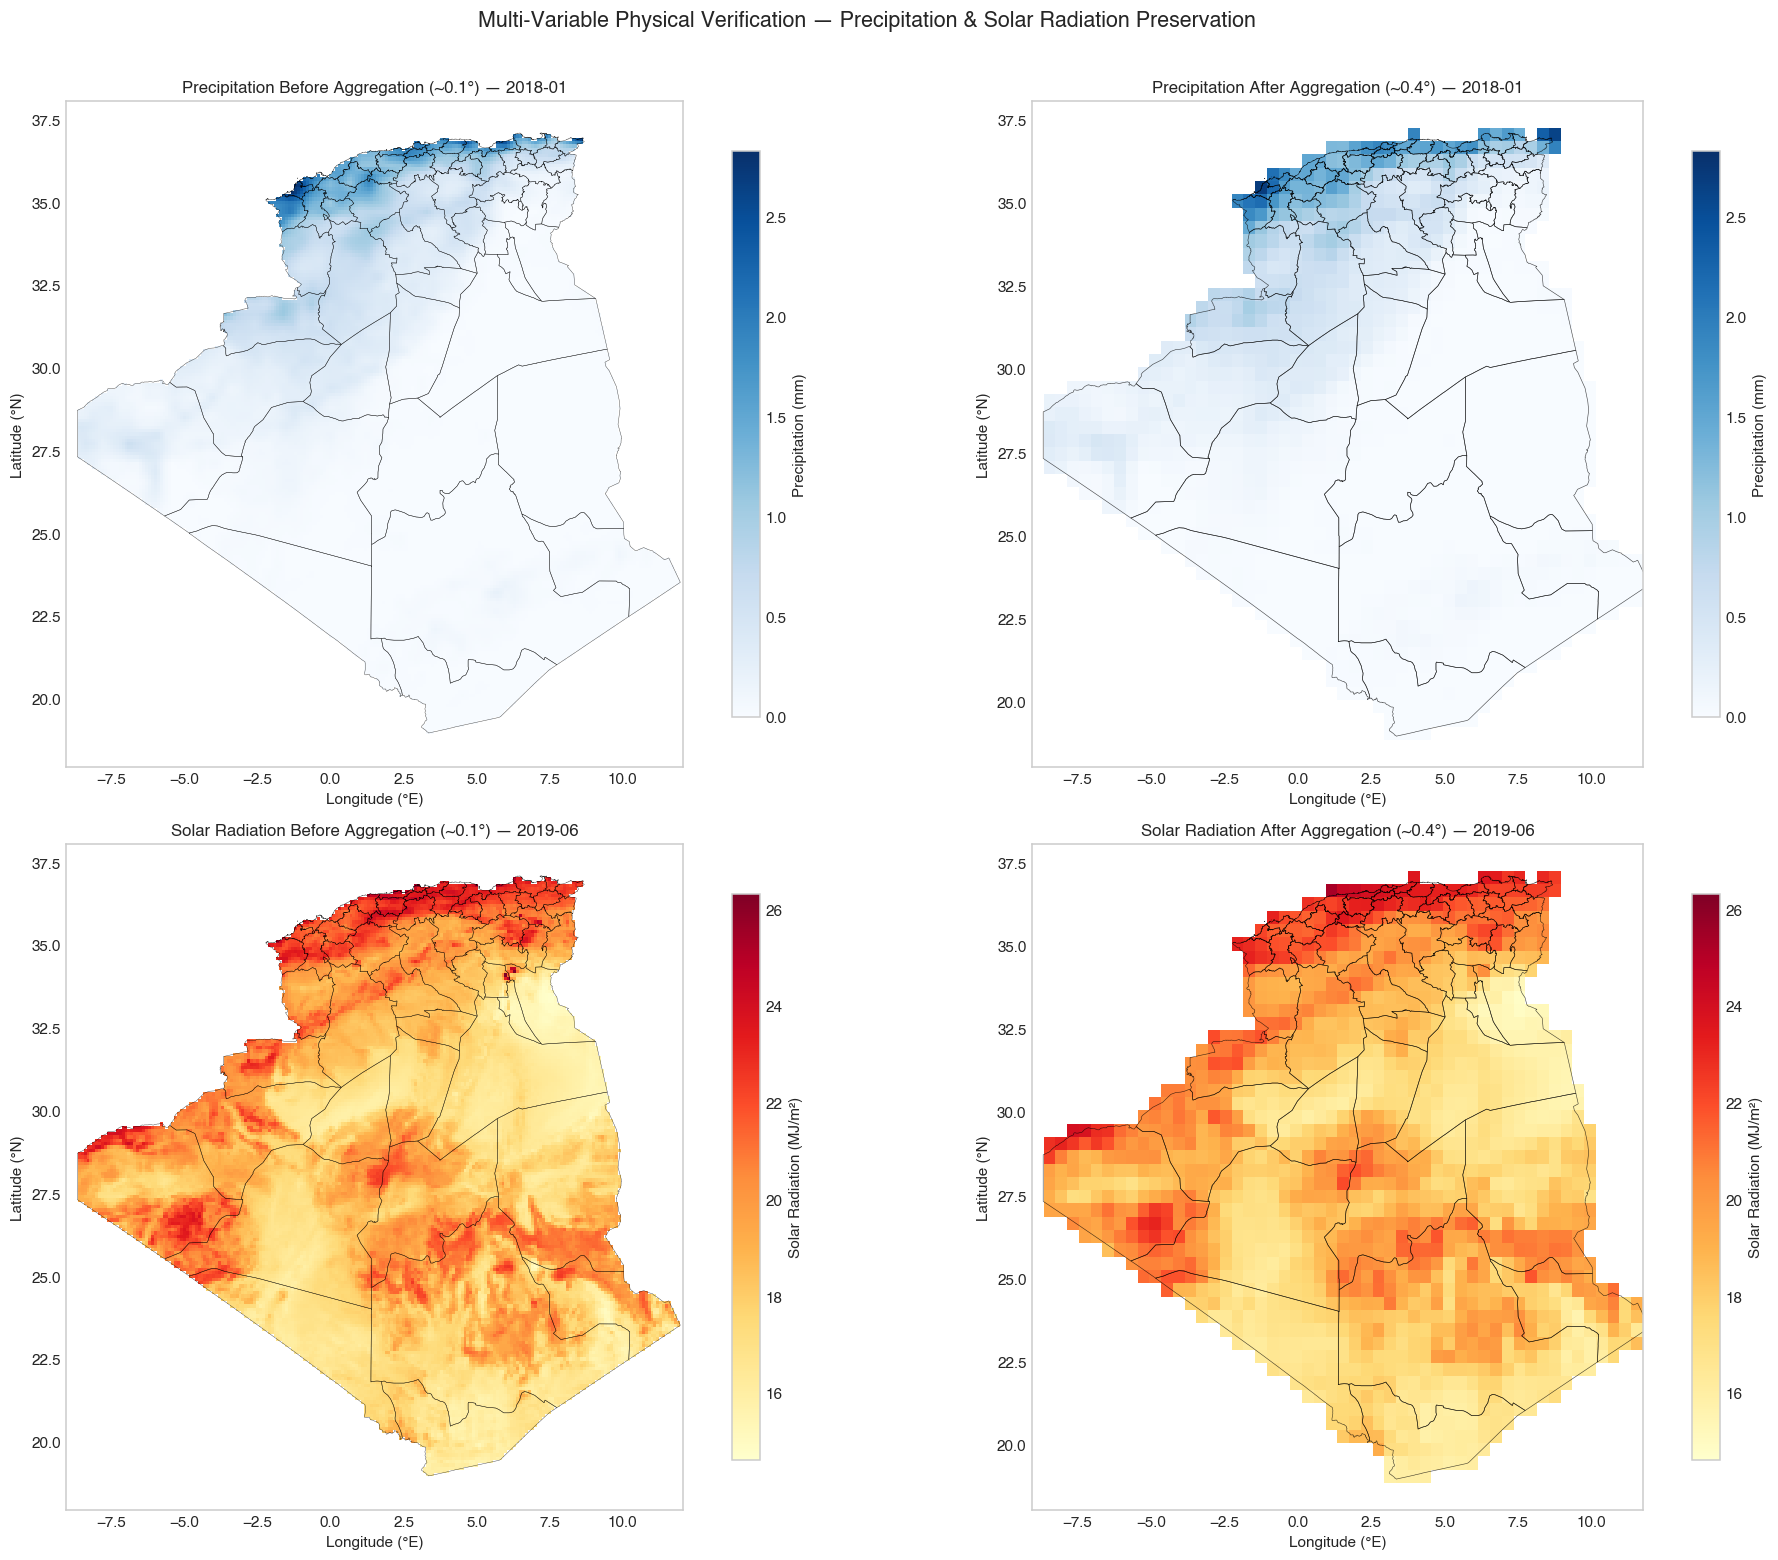

Saved figure: /Users/maria/Desktop/dataminingproject/outputs/figures/aggregation_multivar_comparison.png


In [268]:
fig, axes = plt.subplots(2, 2, figsize=(18, 14))

# Winter precipitation (January 2018) in mm
t_precip_idx = 36
t_precip_label = str(ds.time.values[t_precip_idx])[:7]
tp_native = ds['tp'].isel(time=t_precip_idx) * 1000.0  # m to mm
tp_coarse = ds_coarse['tp'].isel(time=t_precip_idx) * 1000.0

# Summer solar radiation (June 2019) in MJ/m²
t_solar_idx = 53
t_solar_label = str(ds.time.values[t_solar_idx])[:7]
ssr_native = ds['ssr'].isel(time=t_solar_idx) / 1e6  # J/m² to MJ/m²
ssr_coarse = ds_coarse['ssr'].isel(time=t_solar_idx) / 1e6

# Row 1: Total Precipitation (Winter)
tp_vmax = float(max(tp_native.max().values, tp_coarse.max().values))
tp_native.plot(ax=axes[0, 0], cmap='Blues', vmin=0, vmax=tp_vmax, add_colorbar=True, cbar_kwargs={'label': 'Precipitation (mm)', 'shrink': 0.85})
wilayas.boundary.plot(ax=axes[0, 0], color='black', linewidth=0.3, alpha=0.7)
axes[0, 0].set_title(f"Precipitation Before Aggregation (~0.1°) — {t_precip_label}", fontsize=11)

tp_coarse.plot(ax=axes[0, 1], cmap='Blues', vmin=0, vmax=tp_vmax, add_colorbar=True, cbar_kwargs={'label': 'Precipitation (mm)', 'shrink': 0.85})
wilayas.boundary.plot(ax=axes[0, 1], color='black', linewidth=0.4, alpha=0.7)
axes[0, 1].set_title(f"Precipitation After Aggregation (~0.4°) — {t_precip_label}", fontsize=11)

# Row 2: Solar Radiation (Summer)
ssr_vmin = float(min(ssr_native.min().values, ssr_coarse.min().values))
ssr_vmax = float(max(ssr_native.max().values, ssr_coarse.max().values))
ssr_native.plot(ax=axes[1, 0], cmap='YlOrRd', vmin=ssr_vmin, vmax=ssr_vmax, add_colorbar=True, cbar_kwargs={'label': 'Solar Radiation (MJ/m²)', 'shrink': 0.85})
wilayas.boundary.plot(ax=axes[1, 0], color='black', linewidth=0.3, alpha=0.7)
axes[1, 0].set_title(f"Solar Radiation Before Aggregation (~0.1°) — {t_solar_label}", fontsize=11)

ssr_coarse.plot(ax=axes[1, 1], cmap='YlOrRd', vmin=ssr_vmin, vmax=ssr_vmax, add_colorbar=True, cbar_kwargs={'label': 'Solar Radiation (MJ/m²)', 'shrink': 0.85})
wilayas.boundary.plot(ax=axes[1, 1], color='black', linewidth=0.4, alpha=0.7)
axes[1, 1].set_title(f"Solar Radiation After Aggregation (~0.4°) — {t_solar_label}", fontsize=11)

for ax in axes.flat:
    ax.set_xlabel('Longitude (°E)', fontsize=10)
    ax.set_ylabel('Latitude (°N)', fontsize=10)

plt.suptitle('Multi-Variable Physical Verification — Precipitation & Solar Radiation Preservation', fontsize=14, y=1.01, fontweight='bold')
plt.tight_layout()
fig_path6 = FIGURES_DIR / 'aggregation_multivar_comparison.png'
plt.savefig(fig_path6, dpi=150, bbox_inches='tight')
plt.show()
print(f"Saved figure: {fig_path6}")

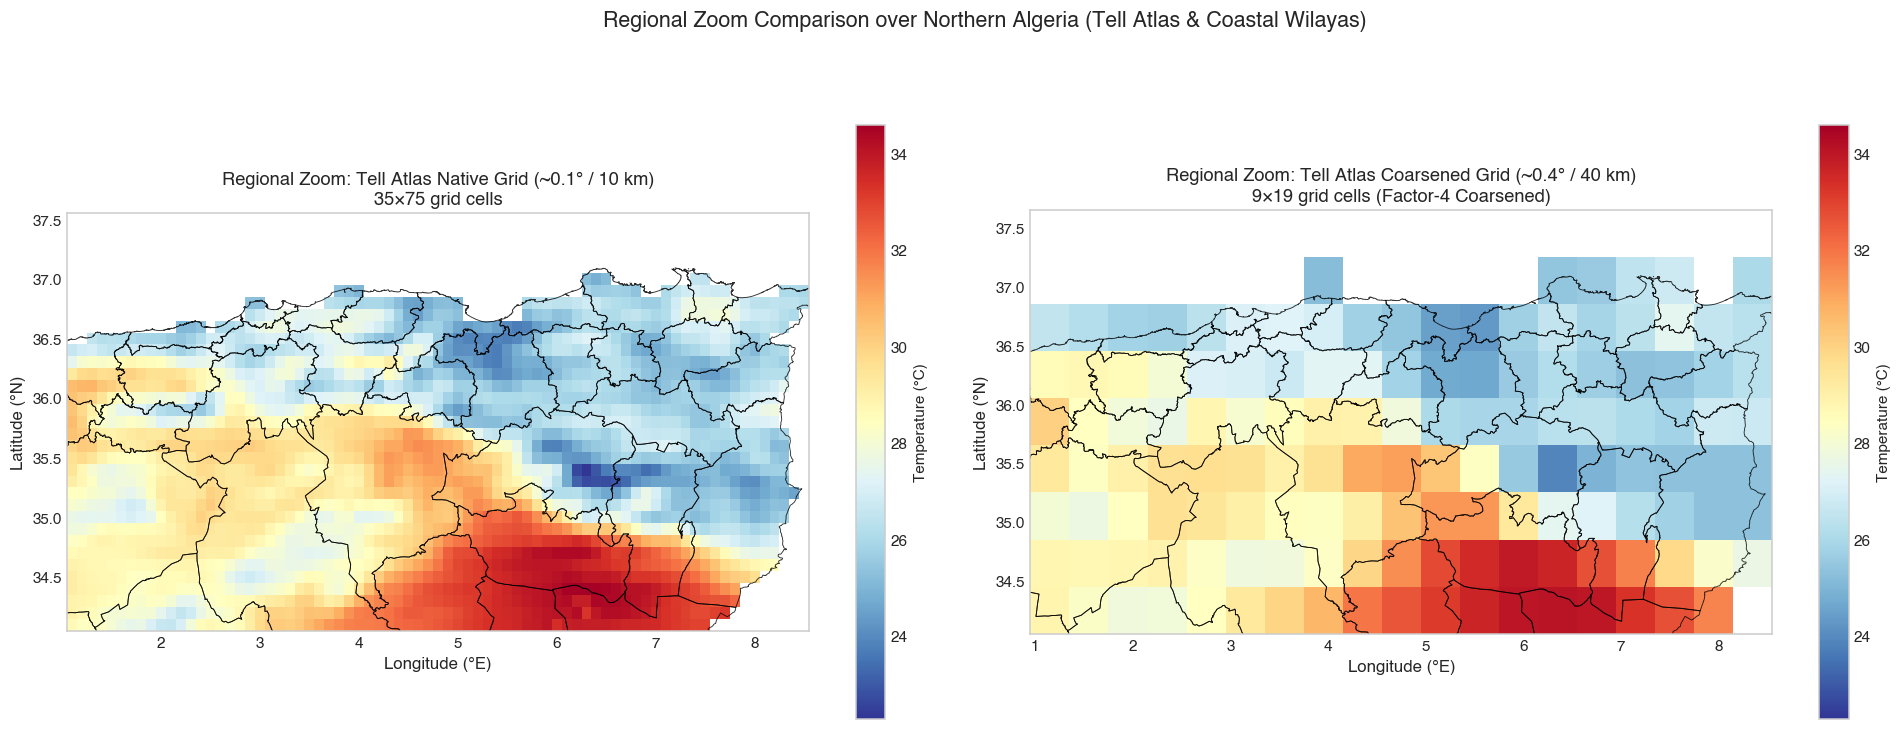

Saved figure: /Users/maria/Desktop/dataminingproject/outputs/figures/aggregation_regional_zoom_comparison.png


In [269]:
lat_slice = slice(37.5, 34.0)
lon_slice = slice(1.0, 8.5)

t2m_zoom_nat = (ds['t2m'].isel(time=66).sel(latitude=lat_slice, longitude=lon_slice) - 273.15)
t2m_zoom_crs = (ds_coarse['t2m'].isel(time=66).sel(latitude=lat_slice, longitude=lon_slice) - 273.15)

zoom_vmin = float(min(t2m_zoom_nat.min().values, t2m_zoom_crs.min().values))
zoom_vmax = float(max(t2m_zoom_nat.max().values, t2m_zoom_crs.max().values))

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

t2m_zoom_nat.plot(ax=axes[0], cmap='RdYlBu_r', vmin=zoom_vmin, vmax=zoom_vmax, add_colorbar=True, cbar_kwargs={'label': 'Temperature (°C)', 'shrink': 0.85})
wilayas.cx[1.0:8.5, 34.0:37.5].boundary.plot(ax=axes[0], color='black', linewidth=0.6, alpha=0.8)
axes[0].set_title(f"Regional Zoom: Tell Atlas Native Grid (~0.1° / 10 km)\n{len(t2m_zoom_nat.latitude)}×{len(t2m_zoom_nat.longitude)} grid cells", fontsize=12)
axes[0].set_xlabel('Longitude (°E)', fontsize=11)
axes[0].set_ylabel('Latitude (°N)', fontsize=11)

t2m_zoom_crs.plot(ax=axes[1], cmap='RdYlBu_r', vmin=zoom_vmin, vmax=zoom_vmax, add_colorbar=True, cbar_kwargs={'label': 'Temperature (°C)', 'shrink': 0.85})
wilayas.cx[1.0:8.5, 34.0:37.5].boundary.plot(ax=axes[1], color='black', linewidth=0.6, alpha=0.8)
axes[1].set_title(f"Regional Zoom: Tell Atlas Coarsened Grid (~0.4° / 40 km)\n{len(t2m_zoom_crs.latitude)}×{len(t2m_zoom_crs.longitude)} grid cells (Factor-4 Coarsened)", fontsize=12)
axes[1].set_xlabel('Longitude (°E)', fontsize=11)
axes[1].set_ylabel('Latitude (°N)', fontsize=11)

plt.suptitle('Regional Zoom Comparison over Northern Algeria (Tell Atlas & Coastal Wilayas)', fontsize=14, y=1.01, fontweight='bold')
plt.tight_layout()
fig_path7 = FIGURES_DIR / 'aggregation_regional_zoom_comparison.png'
plt.savefig(fig_path7, dpi=150, bbox_inches='tight')
plt.show()
print(f"Saved figure: {fig_path7}")